In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, RobustScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, learning_curve

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor


from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

#### Data Observation, Cleaning

In [2]:
df = pd.read_csv('car.csv')

df

,MODEL,MAKE,MODEL.1,VEHICLE CLASS,ENGINE_SIZE,CYLINDERS,TRANSMISSION,FUEL,FUEL_CONSUMPTION*,Unnamed: 9,Unnamed: 10,Unnamed: 11,CO2_EMISSIONS
0,2001,ACURA,1.7EL,COMPACT,1.7,4,A4,X,9.3,7.2,8.3,34,191
1,2001,ACURA,1.7EL,COMPACT,1.7,4,M5,X,8.9,7.4,8.3,34,191
2,2001,ACURA,3.2CL,COMPACT,3.2,6,AS5,Z,13.7,8.8,11.5,25,265
3,2001,ACURA,3.2TL,MID-SIZE,3.2,6,AS5,Z,13.8,8.8,11.6,24,267
4,2001,ACURA,3.5RL,MID-SIZE,3.5,6,A4,Z,15.0,10.9,13.1,22,301
...,...,...,...,...,...,...,...,...,...,...,...,...,...
674,2001,VOLVO,V70 T5 WAGON TURBO,STATION WAGON - MID-SIZE,2.3,5,M5,Z,13.0,9.3,11.3,25,260
675,2001,VOLVO,V70 WAGON,STATION WAGON - MID-SIZE,2.4,5,A5,Z,12.8,9.3,11.2,25,258
676,2001,VOLVO,V70 WAGON,STATION WAGON - MID-SIZE,2.4,5,M5,Z,12.5,9.3,11.0,26,253
677,2001,VOLVO,V70 WAGON AWD TURBO,STATION WAGON - MID-SIZE,2.4,5,AS5,Z,14.4,10.3,12.5,23,288


In [3]:
# standardize columns

df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace(':', '').str.replace('*', '')

In [4]:
df.columns

Index(['model', 'make', 'model.1', 'vehicle_class', 'engine_size', 'cylinders',
       'transmission', 'fuel', 'fuel_consumption', 'unnamed_9', 'unnamed_10',
       'unnamed_11', 'co2_emissions'],
      dtype='object')

In [5]:
df.rename(columns = {'model': 'year',
                     'model.1': 'model',
                    'unnamed_9': 'fuel_consumption2',
                    'unnamed_10': 'fuel_consumption3', 
                    'unnamed_11': 'fuel_consumption4'}, inplace = True)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 679 entries, 0 to 678
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               679 non-null    int64  
 1   make               679 non-null    object 
 2   model              679 non-null    object 
 3   vehicle_class      679 non-null    object 
 4   engine_size        679 non-null    float64
 5   cylinders          679 non-null    int64  
 6   transmission       679 non-null    object 
 7   fuel               679 non-null    object 
 8   fuel_consumption   679 non-null    float64
 9   fuel_consumption2  679 non-null    float64
 10  fuel_consumption3  679 non-null    float64
 11  fuel_consumption4  679 non-null    int64  
 12  co2_emissions      679 non-null    int64  
dtypes: float64(4), int64(4), object(5)
memory usage: 69.1+ KB


In [6]:
df['vehicle_class'].value_counts()

vehicle_class
COMPACT                     145
PICKUP TRUCK - STANDARD     101
SUV                          98
MID-SIZE                     82
SUBCOMPACT                   62
TWO-SEATER                   31
STATION WAGON - MID-SIZE     31
FULL-SIZE                    30
VAN - CARGO                  23
VAN - PASSENGER              18
MINIVAN                      17
MINICOMPACT                  17
STATION WAGON - SMALL        12
PICKUP TRUCK - SMALL         12
Name: count, dtype: int64

In [7]:
df.describe()

,year,engine_size,cylinders,fuel_consumption,fuel_consumption2,fuel_consumption3,fuel_consumption4,co2_emissions
count,679.0,679.000000,679.000000,679.000000,679.000000,679.000000,679.000000,679.000000
mean,2001.0,3.252577,5.798233,14.591900,10.613844,12.802798,23.107511,293.656848
std,0.0,1.203751,1.531073,3.025654,2.357724,2.685590,5.308083,60.372456
min,2001.0,1.000000,3.000000,4.900000,4.000000,4.500000,14.000000,104.000000
25%,2001.0,2.200000,4.000000,12.700000,9.000000,11.000000,19.000000,253.000000
50%,2001.0,3.000000,6.000000,14.300000,10.100000,12.300000,23.000000,283.000000
75%,2001.0,4.200000,6.000000,16.650000,12.500000,14.850000,26.000000,340.000000
max,2001.0,8.000000,12.000000,23.200000,18.000000,20.800000,63.000000,478.000000


In [8]:
df.isnull().sum()

year                 0
make                 0
model                0
vehicle_class        0
engine_size          0
cylinders            0
transmission         0
fuel                 0
fuel_consumption     0
fuel_consumption2    0
fuel_consumption3    0
fuel_consumption4    0
co2_emissions        0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

#### Data Visualization

Text(0, 0.5, 'Manufacturer')

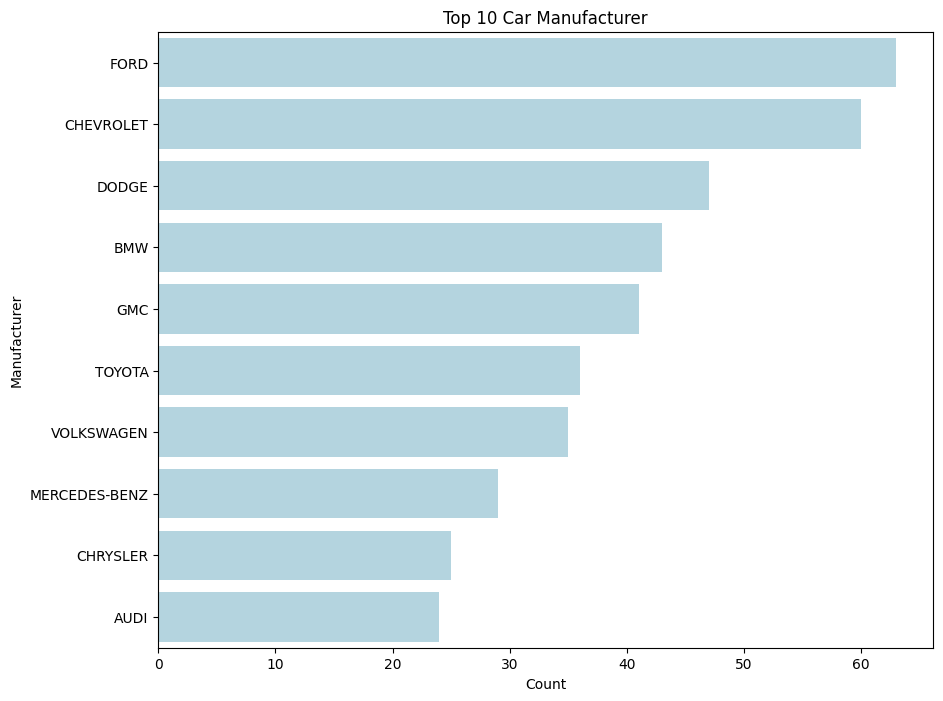

In [10]:
plt.figure(figsize = (10, 8))
sns.countplot(y = 'make', 
            data = df,
            order = df['make'].value_counts().nlargest(10).index,
            color = 'lightblue')
plt.title('Top 10 Car Manufacturer')
plt.xlabel('Count')
plt.ylabel('Manufacturer')

Text(0, 0.5, 'Class')

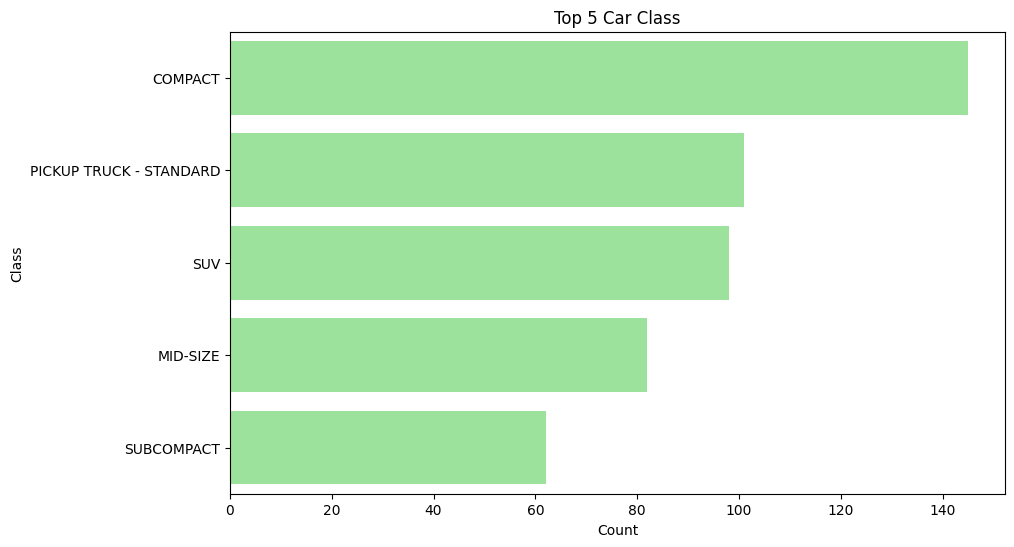

In [11]:
plt.figure(figsize = (10, 6))
sns.countplot(y = 'vehicle_class', 
            data = df,
            order = df['vehicle_class'].value_counts().nlargest(5).index,
            color = 'lightgreen')
plt.title('Top 5 Car Class')
plt.xlabel('Count')
plt.ylabel('Class')

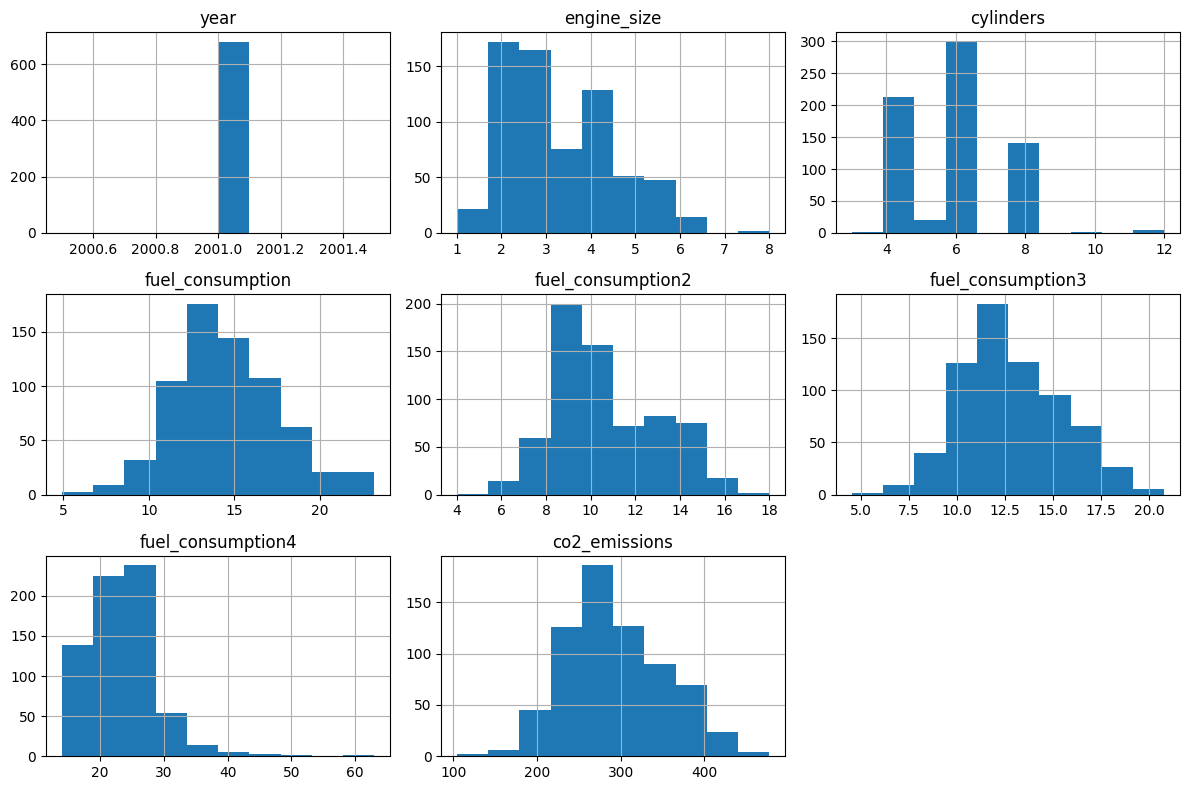

In [12]:
df.hist(figsize = (12, 8))
plt.tight_layout()

C:\Users\Louis Bernal\AppData\Local\Temp\ipykernel_27264\4253048660.py:5: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[column], fill=True, color="skyblue")


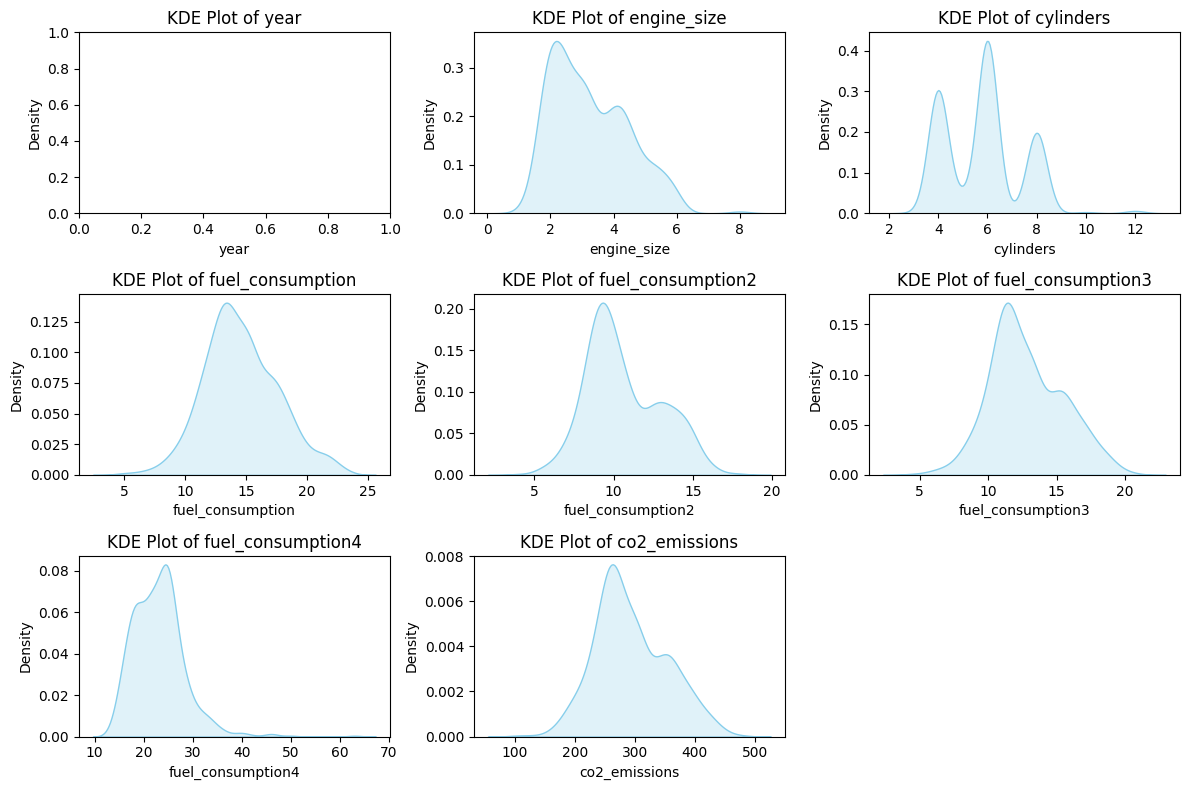

In [13]:
# KDE Plot for each numerical feature to check distribution and skewness
plt.figure(figsize=(12, 8))
for idx, column in enumerate(df.select_dtypes(exclude='object').columns, 1):
    plt.subplot(3, 3, idx)
    sns.kdeplot(df[column], fill=True, color="skyblue")
    plt.title(f"KDE Plot of {column}")
    plt.xlabel(column)
    plt.ylabel("Density")
plt.tight_layout()
plt.show()


Text(0.5, 1.0, 'Correlation Matrix')

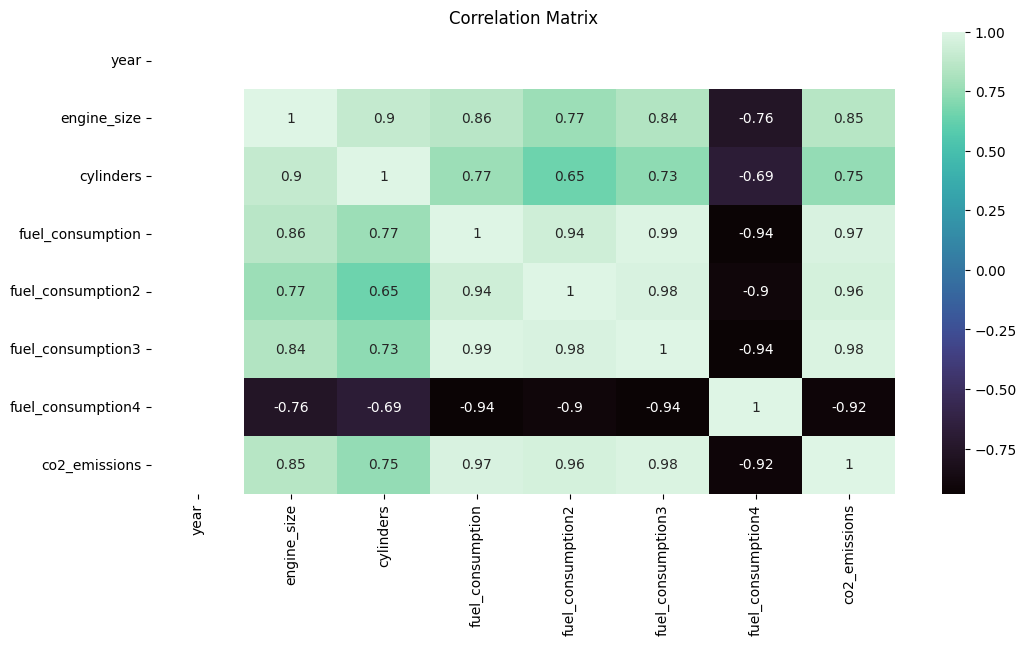

In [14]:
num_df = df.select_dtypes(exclude = 'object')
df_corr = num_df.corr()

plt.figure(figsize = (12, 6))
sns.heatmap(df_corr, annot = True, cmap = 'mako')
plt.title('Correlation Matrix')

#### Data Preprocessing

In [15]:
# drop unnecessary and redundant columns

df.drop(['year', 'fuel_consumption2', 'fuel_consumption3', 'fuel_consumption4'], axis=1, inplace=True)

In [16]:
categorical_cols = df.select_dtypes('object').columns

# apply LabelEncoder to each categorical column
for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

In [17]:
df.columns

Index(['make', 'model', 'vehicle_class', 'engine_size', 'cylinders',
       'transmission', 'fuel', 'fuel_consumption', 'co2_emissions'],
      dtype='object')

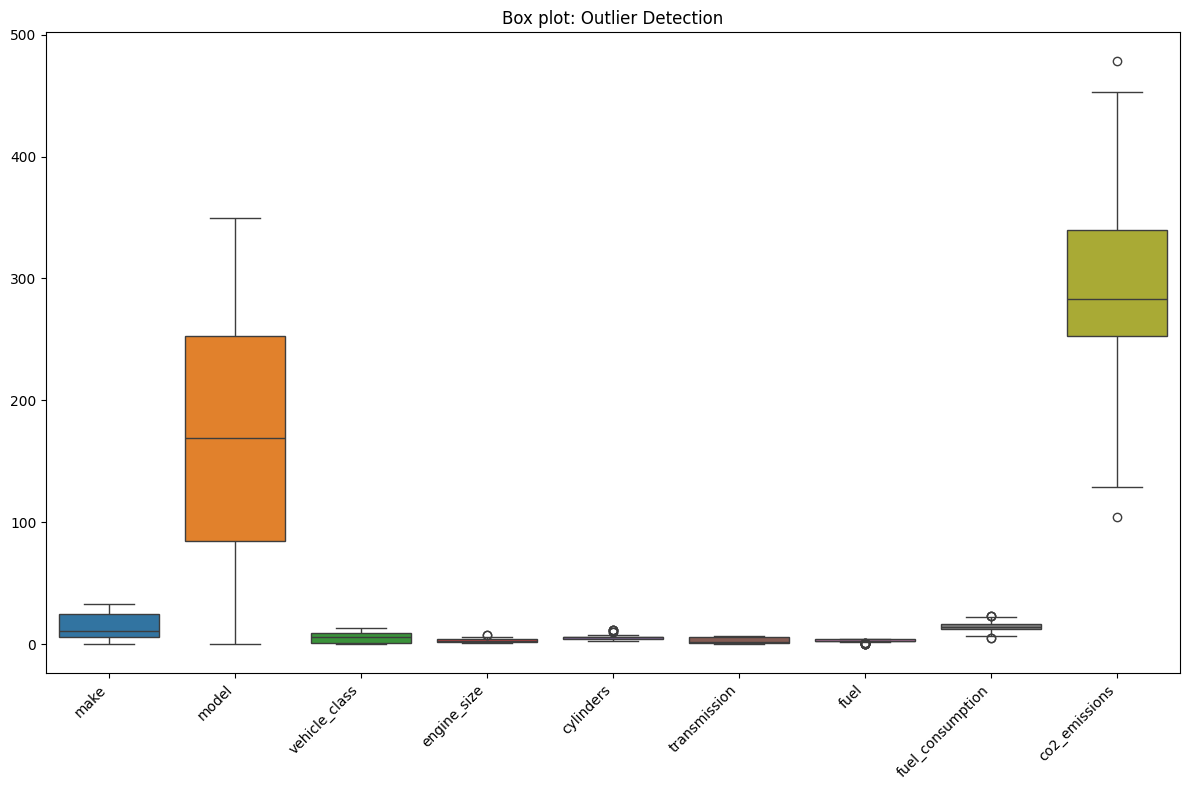

In [18]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=df[['make', 'model', 'vehicle_class', 'engine_size', 'cylinders',
       'transmission', 'fuel', 'fuel_consumption', 'co2_emissions']])

plt.title('Box plot: Outlier Detection')
plt.xticks(rotation=45, ha='right')  
plt.tight_layout()  

plt.show()


In [19]:
# Interquartile Range (IQR) function to remove outliars

data_numeric = df.select_dtypes(exclude='object')

for col in data_numeric.columns:
    q1 = data_numeric[col].quantile(0.25)
    q3 = data_numeric[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - (1.5 * iqr)
    high = q3 + (1.5 * iqr)

    # Count outliers
    outliers = ((data_numeric[col] > high) | (data_numeric[col] < low)).sum()
    total = data_numeric.shape[0]
    print(f"Total outliers in {col} are: {outliers} - {round(100 * (outliers / total), 2)}%")

    if outliers > 0:
        # Filter data to exclude outliers
        df = df.loc[(df[col] <= high) & (df[col] >= low)]

Total outliers in make are: 0 - 0.0%
Total outliers in model are: 0 - 0.0%
Total outliers in vehicle_class are: 0 - 0.0%
Total outliers in engine_size are: 2 - 0.29%
Total outliers in cylinders are: 6 - 0.88%
Total outliers in transmission are: 0 - 0.0%
Total outliers in fuel are: 10 - 1.47%
Total outliers in fuel_consumption are: 5 - 0.74%
Total outliers in co2_emissions are: 2 - 0.29%


In [20]:
# split df into x (independent), y (dependent) variables
x = df.drop(['co2_emissions'], axis = 1).values
y = df['co2_emissions'].values

In [21]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

In [22]:
# robust scaler less sensitive to skewed / data with outliers, ensures stable features
rc = RobustScaler()
x_train = rc.fit_transform(x_train)
x_test= rc.transform(x_test)


#### Data Modeling, Prediction
##### Poly Regression

In [23]:
# Create polynomial features
poly = PolynomialFeatures(degree=2)  
x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.transform(x_test)

In [24]:
# Fit the linear regression model on the polynomial features
poly_lr = LinearRegression()
poly_lr.fit(x_train_poly, y_train)

LinearRegression()

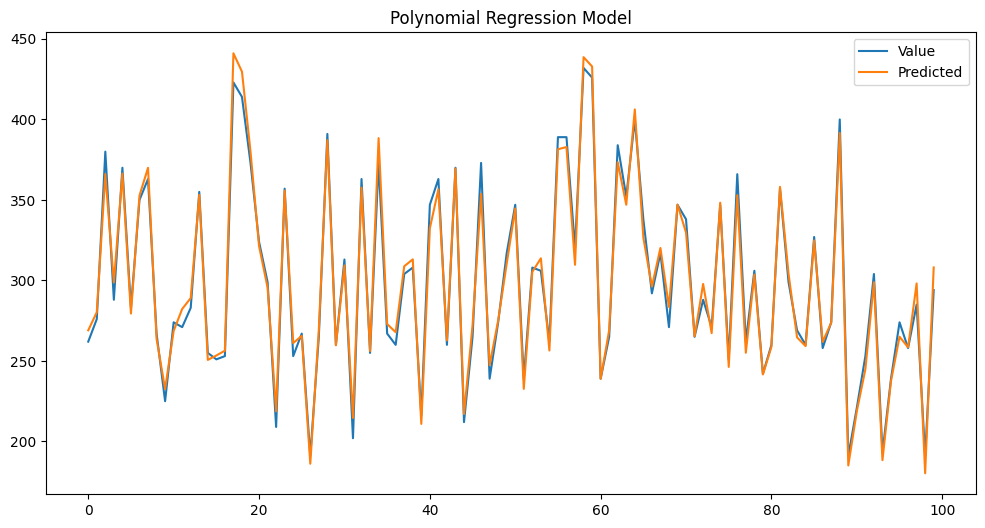

In [25]:
# predict test data
poly_y_pred = poly_lr.predict(x_test_poly)

# plot prediction & test data
linear_plot = pd.DataFrame({'y_test': y_test, 'prediction': poly_y_pred})

plt.figure(figsize=(12,6))
plt.plot(linear_plot[:100])
plt.title('Polynomial Regression Model')
plt.legend(["Value","Predicted"])

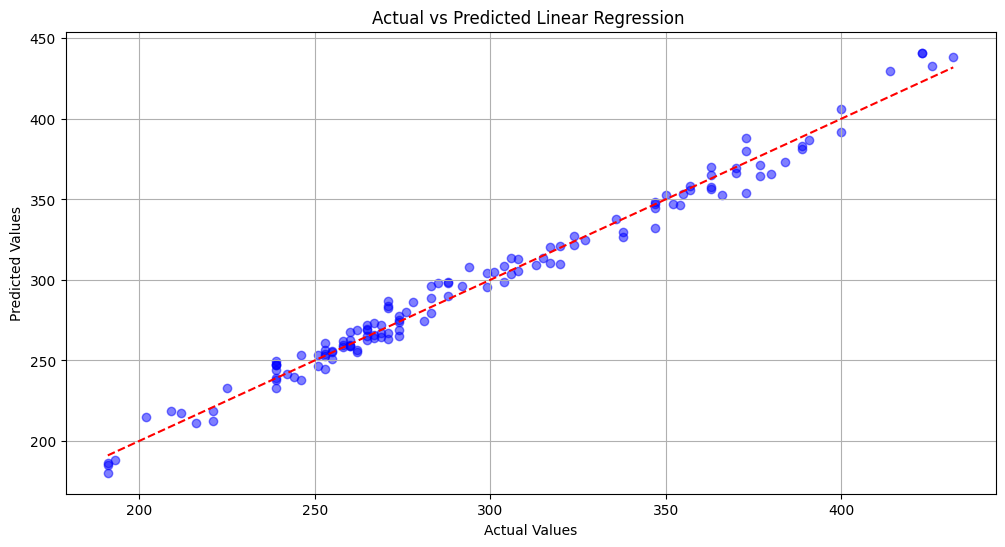

In [26]:
plt.figure(figsize = (12, 6))
plt.scatter(y_test, poly_y_pred, color = 'blue', alpha = 0.5)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()], color = 'red', linestyle = '--')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Linear Regression ')
plt.grid()

In [27]:
# Polynomial Regression value prediction
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': poly_y_pred
})

print(" Polynomial Regression Comparison of Actual vs Predicted Values:")
print(comparison_df)

 Polynomial Regression Comparison of Actual vs Predicted Values:
     Actual   Predicted
0       262  269.026476
1       276  280.274091
2       380  366.060723
3       288  298.698515
4       370  366.415524
..      ...         ...
127     258  259.666572
128     239  249.862747
129     271  263.525654
130     363  364.929329
131     253  252.764398

[132 rows x 2 columns]


##### Random Forest

In [28]:
forest = RandomForestRegressor()
forest.fit(x_train, y_train)

RandomForestRegressor()

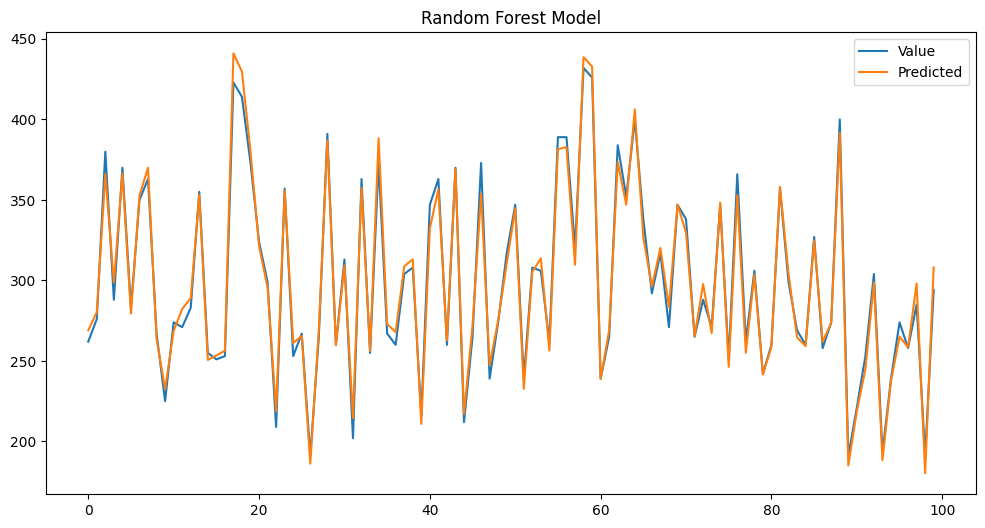

In [29]:
# predict test data
forest_y_pred = forest.predict(x_test)

# plot prediction & test data
forest_plot = pd.DataFrame({'y_test': y_test, 'prediction': forest_y_pred})

plt.figure(figsize=(12,6))
plt.plot(linear_plot[:100])
plt.title('Random Forest Model')
plt.legend(["Value","Predicted"])

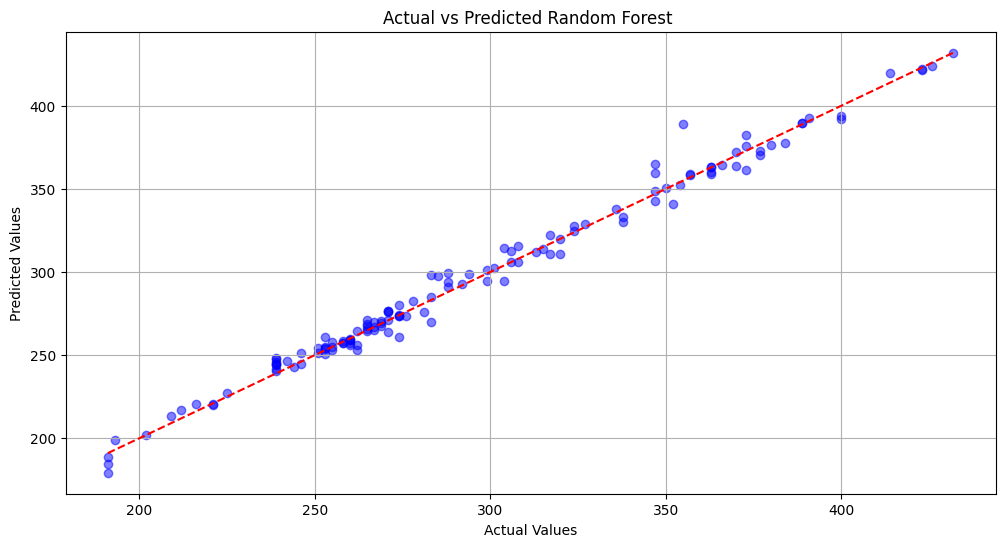

In [30]:
plt.figure(figsize = (12, 6))
plt.scatter(y_test, forest_y_pred, color = 'blue', alpha = 0.5)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()], color = 'red', linestyle = '--')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Random Forest ')
plt.grid()

##### XGBoost

In [31]:
# set xgboost parameters
xg = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    alpha=0.1,
    lambda_=1,
    gamma=0.1
)

# Fit the model with early stopping
xg.fit(
    x_train, y_train,   
# Specify the evaluation metric (e.g., RMSE)
    verbose=True                     
)

c:\Users\Louis Bernal\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\core.py:158: UserWarning: [20:30:11] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0015a694724fa8361-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "lambda_" } are not used.

  warnings.warn(smsg, UserWarning)


XGBRegressor(alpha=0.1, base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=0.1, grow_policy=None, importance_type=None,
             interaction_constraints=None, lambda_=1, learning_rate=0.05,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=3, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1000, n_jobs=None, ...)

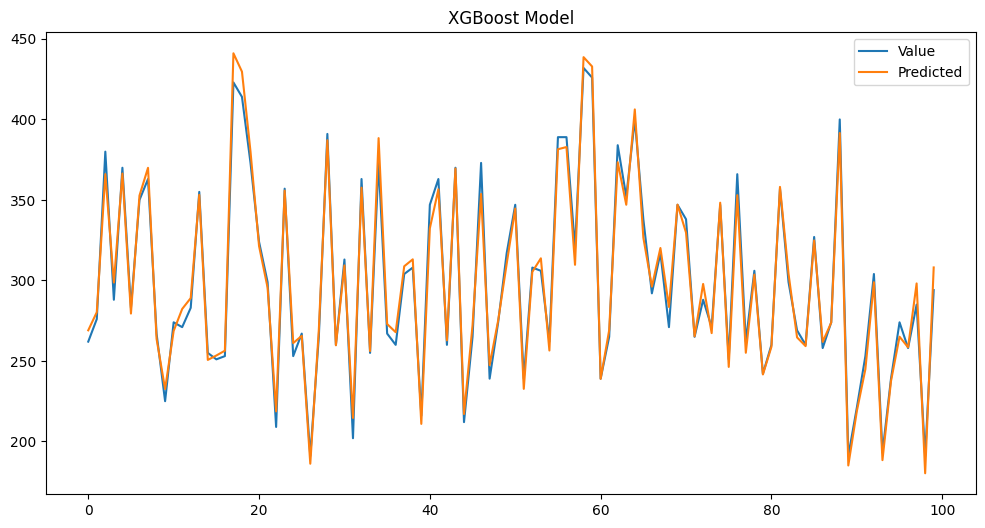

In [32]:
# predict test data
xg_y_pred = xg.predict(x_test)

# plot prediction & test data
xg_plot = pd.DataFrame({'y_test': y_test, 'prediction': xg_y_pred})

plt.figure(figsize=(12,6))
plt.plot(linear_plot[:100])
plt.title('XGBoost Model')
plt.legend(["Value","Predicted"])

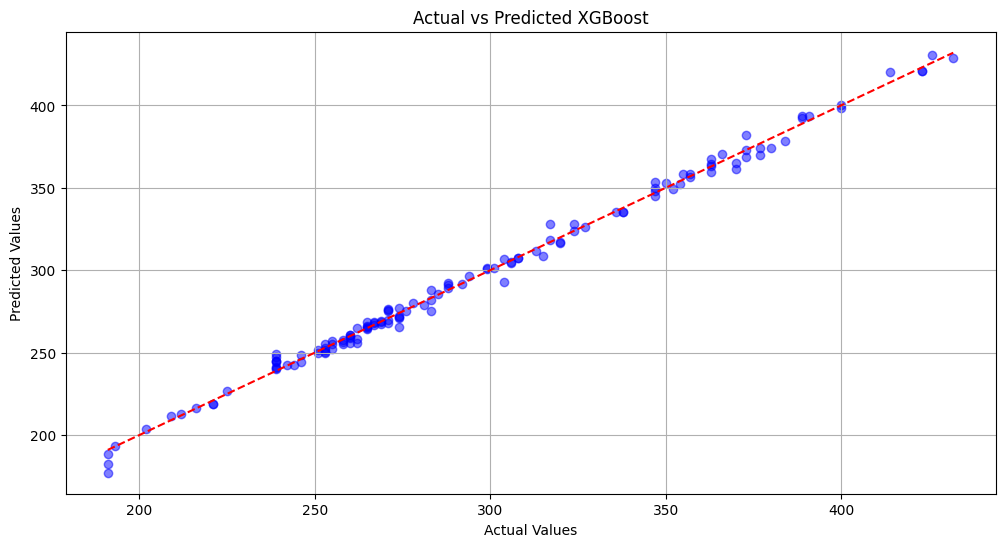

In [33]:
plt.figure(figsize = (12, 6))
plt.scatter(y_test, xg_y_pred, color = 'blue', alpha = 0.5)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()], color = 'red', linestyle = '--')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted XGBoost')
plt.grid()

#### Metrics

In [34]:
lr_r2 = r2_score(y_test, poly_y_pred)
lr_rmse = root_mean_squared_error(y_test, poly_y_pred)
lr_mae= mean_absolute_error(y_test, poly_y_pred)

rf_r2 = r2_score(y_test, forest_y_pred)
rf_rmse = root_mean_squared_error(y_test, forest_y_pred)
rf_mae = mean_absolute_error(y_test, forest_y_pred)

xg_r2 = r2_score(y_test, xg_y_pred)
xg_rmse = root_mean_squared_error(y_test, xg_y_pred)
xg_mae = mean_absolute_error(y_test, xg_y_pred)

models = ['Polynomial Regression', ' Random Forest', 'XGBoost']
data = [[lr_r2,lr_rmse, lr_mae],  [rf_r2, rf_rmse, rf_mae], [xg_r2, xg_rmse, xg_mae]]
cols = ['R2', 'RMSE', 'MAE']
pd.DataFrame(data, columns = cols, index = models).sort_values(ascending = False, by='R2')

,R2,RMSE,MAE
XGBoost,0.995280,3.905955,2.919554
Random Forest,0.988232,6.167729,4.229167
Polynomial Regression,0.983547,7.292920,5.876350


In [35]:
pr_data = {
    'Polynomial Regression ': poly_y_pred[:5],
    'Random Forest ': forest_y_pred[:5],
    'XGBoost ': xg_y_pred[:5],
    'Actual ': y_test[:5]
}
prediction = pd.DataFrame(pr_data)

# Display the DataFrame
print('Model Prediction vs Actual Values')
prediction

Model Prediction vs Actual Values


,Polynomial Regression,Random Forest,XGBoost,Actual
0,269.026476,264.70,264.662811,262
1,280.274091,273.63,275.193970,276
2,366.060723,376.51,374.100403,380
3,298.698515,293.73,292.454315,288
4,366.415524,363.64,361.368347,370


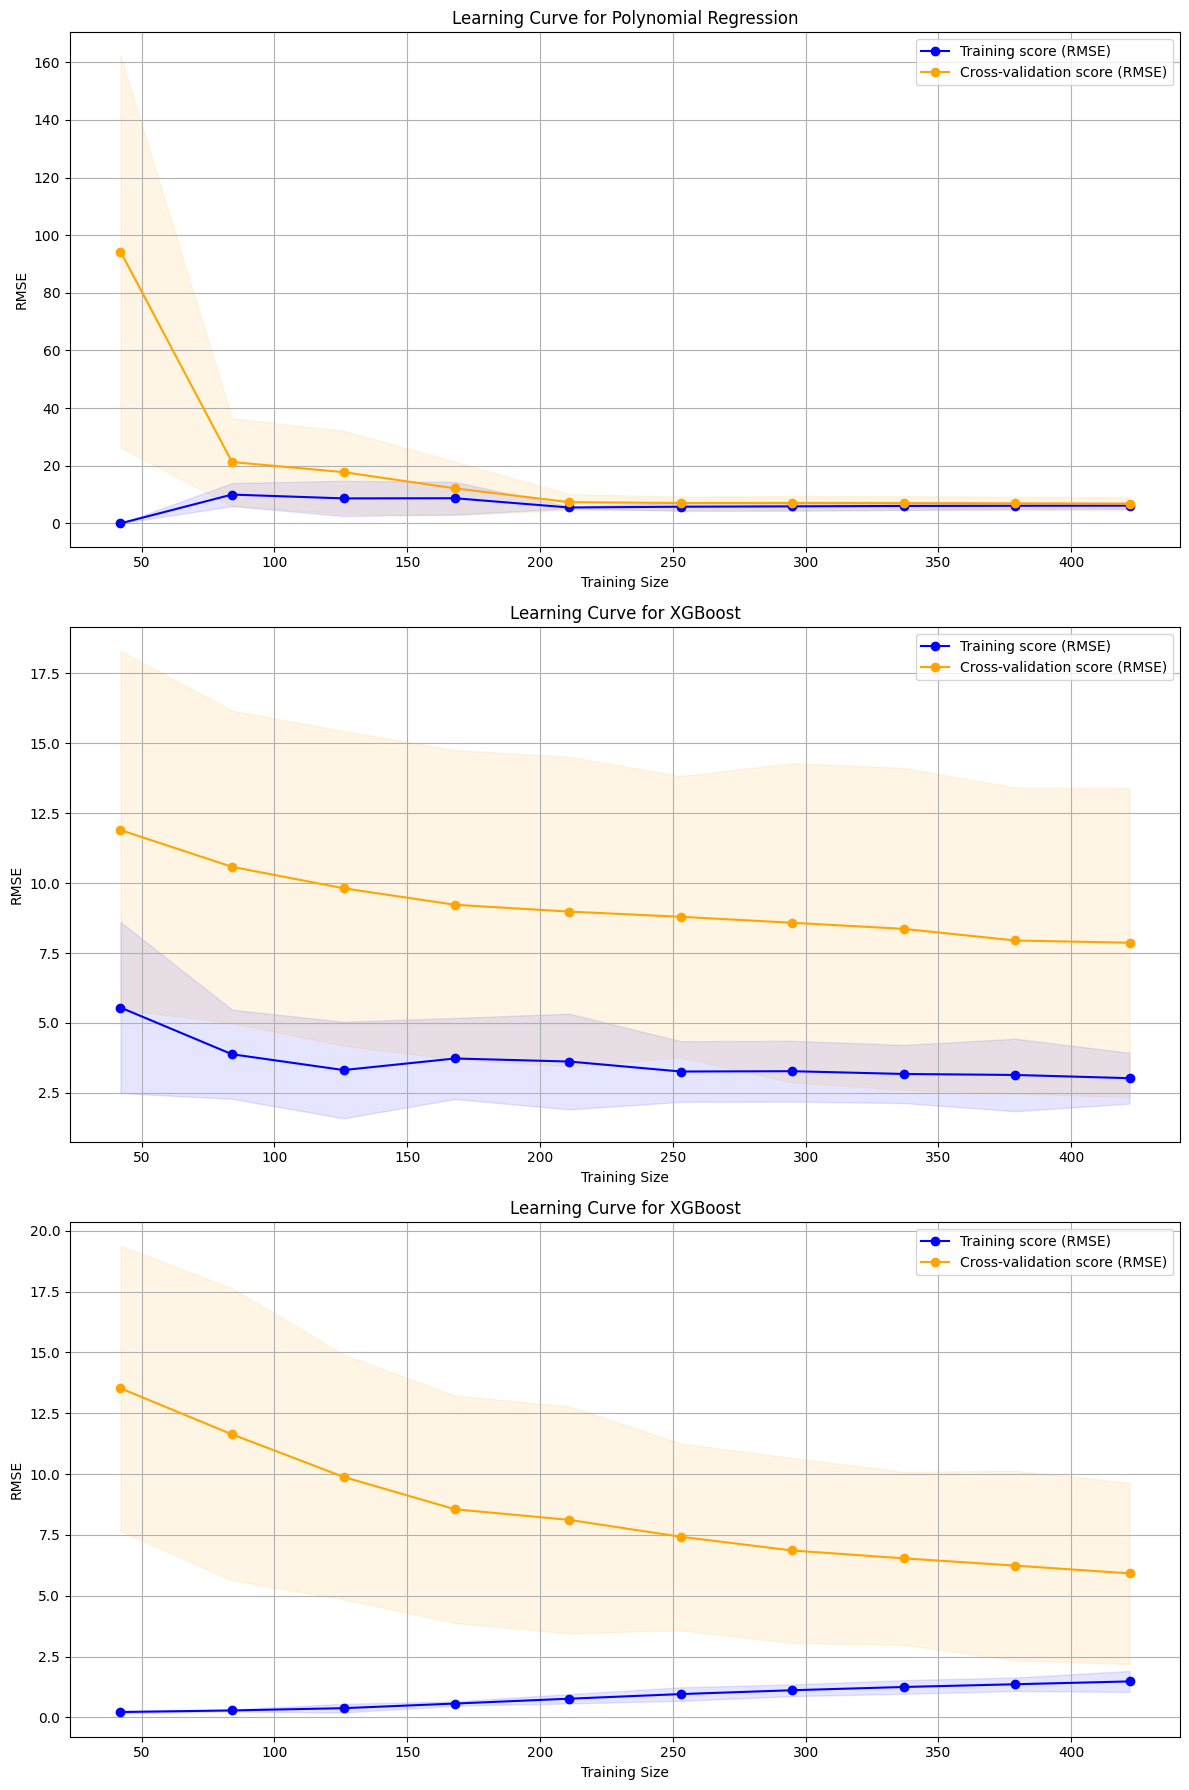

In [36]:
# Define a function to plot learning curves for Polynomial Regression
def plot_learning_curve_poly(poly_lr, x_train_poly, y_train, ax):
    train_sizes, train_scores, val_scores = learning_curve(poly_lr, x_train_poly, y_train, cv=5, n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10),
        scoring='neg_mean_squared_error'
    )
    
    # Calculate RMSE
    train_scores_mean = np.sqrt(-train_scores.mean(axis=1))  # Take the square root
    val_scores_mean = np.sqrt(-val_scores.mean(axis=1))      
    train_scores_std = np.sqrt(train_scores.std(axis=1))
    val_scores_std = np.sqrt(val_scores.std(axis=1))

    # Plotting
    ax.plot(train_sizes, train_scores_mean, 'o-', color='blue', label='Training score (RMSE)')
    ax.plot(train_sizes, val_scores_mean, 'o-', color='orange', label='Cross-validation score (RMSE)')
    
    # Confidence intervals
    ax.fill_between(train_sizes, 
                     train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, 
                     alpha=0.1, color='blue')
    ax.fill_between(train_sizes, 
                     val_scores_mean - val_scores_std,
                     val_scores_mean + val_scores_std, 
                     alpha=0.1, color='orange')
    
    ax.set_title('Learning Curve for Polynomial Regression')
    ax.set_xlabel('Training Size')
    ax.set_ylabel('RMSE')
    ax.legend(loc='best')
    ax.grid()

# Define a function to plot learning curves for Random Forest
def plot_learning_curve(forest, x, y, ax):
    train_sizes, train_scores, val_scores = learning_curve(forest, x, y, cv=5, n_jobs=-1,
                                                            train_sizes=np.linspace(0.1, 1.0, 10),
                                                            scoring='neg_mean_squared_error')
    
    # Calculate the mean and standard deviation for training scores
    train_scores_mean = np.sqrt(-train_scores.mean(axis=1))
    val_scores_mean = np.sqrt(-val_scores.mean(axis=1))
    train_scores_std = np.sqrt(train_scores.std(axis=1))
    val_scores_std = np.sqrt(val_scores.std(axis=1))

    # Plotting
    ax.plot(train_sizes, train_scores_mean, 'o-', color='blue', label='Training score (RMSE)')
    ax.plot(train_sizes, val_scores_mean, 'o-', color='orange', label='Cross-validation score (RMSE)')
    
    # Plot the confidence intervals
    ax.fill_between(train_sizes, 
                     train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, 
                     alpha=0.1, color='blue')
    ax.fill_between(train_sizes, 
                     val_scores_mean - val_scores_std,
                     val_scores_mean + val_scores_std, 
                     alpha=0.1, color='orange')
    
    ax.set_title('Learning Curve for Random Forest')
    ax.set_xlabel('Training Size')
    ax.set_ylabel('RMSE')
    ax.legend(loc='best')
    ax.grid()

# Define a function to plot learning curves for XGBoost
def plot_learning_curve(xg, x, y, ax):
    train_sizes, train_scores, val_scores = learning_curve(xg, x, y, cv=5, n_jobs=-1,
                                                            train_sizes=np.linspace(0.1, 1.0, 10),
                                                            scoring='neg_mean_squared_error')
    
    # Calculate the mean and standard deviation for training scores
    train_scores_mean = np.sqrt(-train_scores.mean(axis=1))
    val_scores_mean = np.sqrt(-val_scores.mean(axis=1))
    train_scores_std = np.sqrt(train_scores.std(axis=1))
    val_scores_std = np.sqrt(val_scores.std(axis=1))

    # Plotting
    ax.plot(train_sizes, train_scores_mean, 'o-', color='blue', label='Training score (RMSE)')
    ax.plot(train_sizes, val_scores_mean, 'o-', color='orange', label='Cross-validation score (RMSE)')
    
    # Plot the confidence intervals
    ax.fill_between(train_sizes, 
                     train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, 
                     alpha=0.1, color='blue')
    ax.fill_between(train_sizes, 
                     val_scores_mean - val_scores_std,
                     val_scores_mean + val_scores_std, 
                     alpha=0.1, color='orange')
    
    ax.set_title('Learning Curve for XGBoost')
    ax.set_xlabel('Training Size')
    ax.set_ylabel('RMSE')
    ax.legend(loc='best')
    ax.grid()

# Create subplots
fig, axs = plt.subplots(3, 1, figsize=(12, 18))

# Call the functions to plot the learning curves
plot_learning_curve_poly(poly_lr, x_train_poly, y_train, axs[0])
plot_learning_curve(forest, x_train, y_train, axs[1])
plot_learning_curve(xg, x_train, y_train, axs[2])

plt.tight_layout()
plt.show()
